In [1]:

from pathlib import Path
import torch
import pandas as pd
import json
import os

# Project paths
PROJECT_DIR = Path.cwd().parent
NOTEBOOK_DIR = Path.cwd()

CHECKPOINT_DIR = NOTEBOOK_DIR / "checkpoints"
FEATURE_DIR = NOTEBOOK_DIR / "cached_features"

print("Project directory:", PROJECT_DIR)
print("Notebook directory:", NOTEBOOK_DIR)
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Device: CPU")


Project directory: C:\Users\rajva\Desktop\image-captioning Project
Notebook directory: C:\Users\rajva\Desktop\image-captioning Project\notebook
PyTorch version: 2.13.0+cpu
CUDA available: False
Device: CPU


In [2]:

# Check available checkpoints and cached features

print("=== Checkpoints ===")
if CHECKPOINT_DIR.exists():
    for file in CHECKPOINT_DIR.iterdir():
        print(file.name)
else:
    print("Checkpoint folder not found.")

print("\n=== Cached Features ===")
if FEATURE_DIR.exists():
    for file in FEATURE_DIR.iterdir():
        print(file.name)
else:
    print("Cached feature folder not found.")

print("\n=== Possible Evaluation Files ===")
for file in NOTEBOOK_DIR.glob("*.json"):
    print(file.name)


=== Checkpoints ===
best_baseline_model.pth

=== Cached Features ===
test_features.pt
train_features.pt
val_features.pt

=== Possible Evaluation Files ===
baseline_metrics.json
baseline_predictions.json
vit_transformer_metrics.json
vit_transformer_predictions.json
vocabulary.json


In [3]:
print("Searching for model checkpoints...\n")

for file in PROJECT_DIR.rglob("*.pth"):
    print(file)

for file in PROJECT_DIR.rglob("*.pt"):
    if "feature" not in file.name.lower():
        print(file)

Searching for model checkpoints...

C:\Users\rajva\Desktop\image-captioning Project\notebook\checkpoints\best_baseline_model.pth
C:\Users\rajva\Desktop\image-captioning Project\notebook\checkpoints_vit_transformer\best_vit_transformer.pth


## Load Phase 3 predictions and evaluation metrics

In [4]:

# Load Phase 3 evaluation results

metrics_path = NOTEBOOK_DIR / "vit_transformer_metrics.json"
predictions_path = NOTEBOOK_DIR / "vit_transformer_predictions.json"

with open(metrics_path, "r", encoding="utf-8") as f:
    vit_metrics = json.load(f)

with open(predictions_path, "r", encoding="utf-8") as f:
    vit_predictions = json.load(f)

print("=== ViT + Transformer Metrics ===")
print(json.dumps(vit_metrics, indent=2))

print("\n=== Prediction Data Type ===")
print(type(vit_predictions))

print("\n=== First Prediction Examples ===")
if isinstance(vit_predictions, dict):
    for i, (key, value) in enumerate(vit_predictions.items()):
        print(key, ":", value)
        if i == 2:
            break
elif isinstance(vit_predictions, list):
    for item in vit_predictions[:3]:
        print(item)


=== ViT + Transformer Metrics ===
{
  "BLEU-1": 0.5241445006228476,
  "BLEU-2": 0.3614878816932059,
  "BLEU-3": 0.24089649668615595,
  "BLEU-4": 0.1582789001484144,
  "METEOR": 0.40551790524627285,
  "ROUGE-L": 0.41493771126821355
}

=== Prediction Data Type ===
<class 'dict'>

=== First Prediction Examples ===
1056338697_4f7d7ce270.jpg : a girl in a blue shirt is jumping into the air.
106490881_5a2dd9b7bd.jpg : a boy in a blue shirt is running in the ocean.
1082379191_ec1e53f996.jpg : a man sitting on a bench in the middle of a boat on a lake.


In [5]:

# Inspect the first prediction and available dataset files

first_image = next(iter(vit_predictions))

print("Sample image:", first_image)
print("Generated caption:", vit_predictions[first_image])

print("\n=== Dataset Files ===")
for path in PROJECT_DIR.rglob("captions.txt"):
    print("Captions file:", path)

for path in PROJECT_DIR.rglob("*split*"):
    if path.is_file():
        print("Possible split file:", path)


Sample image: 1056338697_4f7d7ce270.jpg
Generated caption: a girl in a blue shirt is jumping into the air.

=== Dataset Files ===
Captions file: C:\Users\rajva\Desktop\image-captioning Project\data\raw\captions.txt


In [8]:

# Load captions robustly

captions_path = PROJECT_DIR / "data" / "raw" / "captions.txt"

rows = []
bad_lines = []

with open(captions_path, "r", encoding="utf-8") as f:
    for line_no, line in enumerate(f, start=1):
        line = line.strip()

        if not line or line.lower().startswith("image,caption"):
            continue

        if "\t" in line:
            image, caption = line.split("\t", 1)
        elif "," in line:
            image, caption = line.split(",", 1)
        else:
            bad_lines.append(line_no)
            continue

        rows.append((image.strip(), caption.strip()))

captions_df = pd.DataFrame(rows, columns=["image", "caption"])

print("Dataset shape:", captions_df.shape)
print("Columns:", captions_df.columns.tolist())
print("\nFirst 5 rows:")
print(captions_df.head())
print("\nUnique images:", captions_df["image"].nunique())
print("Unparsed lines:", len(bad_lines))


Dataset shape: (40460, 2)
Columns: ['image', 'caption']

First 5 rows:
                         image  \
0  1000268201_693b08cb0e.jpg#0   
1  1000268201_693b08cb0e.jpg#1   
2  1000268201_693b08cb0e.jpg#2   
3  1000268201_693b08cb0e.jpg#3   
4  1000268201_693b08cb0e.jpg#4   

                                             caption  
0  A child in a pink dress is climbing up a set o...  
1              A girl going into a wooden building .  
2   A little girl climbing into a wooden playhouse .  
3  A little girl climbing the stairs to her playh...  
4  A little girl in a pink dress going into a woo...  

Unique images: 40460
Unparsed lines: 0


In [9]:

# Remove caption IDs such as #0, #1, etc.
captions_df["image"] = captions_df["image"].str.split("#").str[0]

# Group all reference captions for each image
reference_captions = captions_df.groupby("image")["caption"].apply(list).to_dict()

print("Unique images:", len(reference_captions))

sample_image = next(iter(reference_captions))
print("\nSample image:", sample_image)
print("Number of reference captions:", len(reference_captions[sample_image]))

for i, caption in enumerate(reference_captions[sample_image], start=1):
    print(f"{i}. {caption}")


Unique images: 8092

Sample image: 1000268201_693b08cb0e.jpg
Number of reference captions: 5
1. A child in a pink dress is climbing up a set of stairs in an entry way .
2. A girl going into a wooden building .
3. A little girl climbing into a wooden playhouse .
4. A little girl climbing the stairs to her playhouse .
5. A little girl in a pink dress going into a wooden cabin .


## Detect possible hallucinations using caption comparisons

In [10]:

import re
from collections import Counter

# Simple object/action vocabulary for initial screening
concepts = [
    "person", "man", "woman", "boy", "girl", "child", "people",
    "dog", "cat", "bird", "horse", "cow", "sheep",
    "car", "bus", "truck", "bicycle", "motorcycle", "train", "boat",
    "ball", "skateboard", "surfboard", "snowboard", "skis",
    "water", "beach", "ocean", "lake", "river",
    "bench", "chair", "table", "building", "house", "playhouse",
    "shirt", "dress", "hat", "helmet",
    "running", "walking", "jumping", "sitting", "standing",
    "riding", "playing", "swimming", "surfing", "skiing"
]

def find_concepts(text):
    text = text.lower()
    found = set()

    for concept in concepts:
        pattern = r"\b" + re.escape(concept) + r"\b"
        if re.search(pattern, text):
            found.add(concept)

    return found

# Compare generated captions with reference captions
results = []

for image, generated_caption in vit_predictions.items():
    refs = reference_captions.get(image, [])

    generated_concepts = find_concepts(generated_caption)
    reference_concepts = set()

    for ref in refs:
        reference_concepts.update(find_concepts(ref))

    unsupported = generated_concepts - reference_concepts

    results.append({
        "image": image,
        "generated_caption": generated_caption,
        "generated_concepts": sorted(generated_concepts),
        "reference_concepts": sorted(reference_concepts),
        "unsupported_concepts": sorted(unsupported),
        "unsupported_count": len(unsupported)
    })

hallucination_df = pd.DataFrame(results)

print("Predictions analyzed:", len(hallucination_df))
print("Images with unsupported concepts:",
      (hallucination_df["unsupported_count"] > 0).sum())

print("\nTop 10 suspicious captions:")
display(
    hallucination_df.sort_values(
        "unsupported_count", ascending=False
    ).head(10)
)


Predictions analyzed: 1000
Images with unsupported concepts: 701

Top 10 suspicious captions:


,image,generated_caption,generated_concepts,reference_concepts,unsupported_concepts,unsupported_count
682,3388330419_85d72f7cda.jpg,a girl in a red dress is standing in front of ...,"[dress, girl, house, man, standing, woman]","[house, playing]","[dress, girl, man, standing, woman]",5
830,363617160_6cb0c723be.jpg,a boy in a blue shirt is playing with a red ba...,"[ball, boy, building, playing, shirt]",[girl],"[ball, boy, building, playing, shirt]",5
356,2715035273_8fc8b1291c.jpg,a woman in a black jacket and white dress is s...,"[dress, man, standing, woman]",[walking],"[dress, man, standing, woman]",4
476,3025549604_38b86198f5.jpg,a man and woman are sitting on a bench in fron...,"[bench, man, people, sitting, woman]",[sitting],"[bench, man, people, woman]",4
177,2265096094_8cc34d669c.jpg,a group of people are riding a horse in the ai...,"[dog, horse, man, people, riding]","[boy, car, man, person]","[dog, horse, people, riding]",4
681,3387542157_81bfd00072.jpg,a young boy in a red shirt is running with a b...,"[ball, boy, running, shirt]","[girl, woman]","[ball, boy, running, shirt]",4
712,3442242092_e579538d82.jpg,a woman in a white shirt and a man in a black ...,"[man, shirt, standing, woman]","[girl, walking]","[man, shirt, standing, woman]",4
558,3185371756_ff4e9fa8a6.jpg,a man in a blue shirt is wearing a red shirt a...,"[dog, man, shirt, standing]","[girl, hat, person, woman]","[dog, man, shirt, standing]",4
873,3767841911_6678052eb6.jpg,a boy in a red shirt is playing with a red ball.,"[ball, boy, playing, shirt]","[child, dress, girl, running, standing, water]","[ball, boy, playing, shirt]",4
46,1389264266_8170bc1c54.jpg,a woman in a red dress is standing in front of...,"[building, dress, standing, woman]","[girl, shirt, walking]","[building, dress, standing, woman]",4


Image: 439037721_cdf1fc7358.jpg
Generated caption: a man is standing on a cliff overlooking the water.
Unsupported concepts: ['man', 'standing', 'water']

Reference captions:
1. Two men sitting on the bank of a lake with an ice chest .
2. Two people having a picnic by a lake .
3. Two people having a picnic by the shore .
4. Two people sitting on grass in front of a lake looking at the sky .
5. Two people with hats looking at a lake while sitting on a yellow-grassed hill .


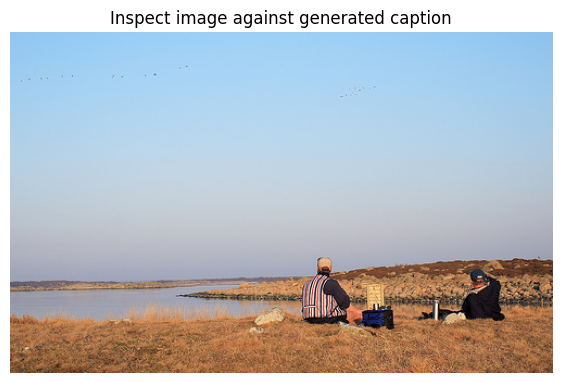

In [16]:
#Inspect flagged images directly

import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

IMAGE_DIR = PROJECT_DIR / "data" / "raw" / "Images"

# Select the most suspicious example
sample = hallucination_df.sort_values(
    "unsupported_count", ascending=False
).iloc[24]

image_path = IMAGE_DIR / sample["image"]

print("Image:", sample["image"])
print("Generated caption:", sample["generated_caption"])
print("Unsupported concepts:", sample["unsupported_concepts"])
print("\nReference captions:")

for i, caption in enumerate(
    reference_captions.get(sample["image"], []), start=1
):
    print(f"{i}. {caption}")

if image_path.exists():
    img = Image.open(image_path).convert("RGB")
    plt.figure(figsize=(7, 5))
    plt.imshow(img)
    plt.axis("off")
    plt.title("Inspect image against generated caption")
    plt.show()
else:
    print("Image not found:", image_path)


In [17]:

# Calculate reference concept coverage for each generated caption

def calculate_coverage(row):
    generated = set(row["generated_concepts"])
    supported = generated.intersection(
        set(row["reference_concepts"])
    )

    if not generated:
        return 1.0

    return len(supported) / len(generated)

hallucination_df["reference_concept_coverage"] = (
    hallucination_df.apply(calculate_coverage, axis=1)
)

hallucination_df["reference_mismatch_flag"] = (
    hallucination_df["reference_concept_coverage"] < 0.5
)

print("Mean reference concept coverage:",
      round(hallucination_df["reference_concept_coverage"].mean(), 3))

print("Captions flagged for low reference coverage:",
      int(hallucination_df["reference_mismatch_flag"].sum()))

print("\nExample:")
display(
    hallucination_df[
        hallucination_df["image"] == "439037721_cdf1fc7358.jpg"
    ][[
        "image",
        "generated_caption",
        "generated_concepts",
        "reference_concepts",
        "reference_concept_coverage",
        "reference_mismatch_flag"
    ]]
)


Mean reference concept coverage: 0.552
Captions flagged for low reference coverage: 359

Example:


,image,generated_caption,generated_concepts,reference_concepts,reference_concept_coverage,reference_mismatch_flag
897,439037721_cdf1fc7358.jpg,a man is standing on a cliff overlooking the w...,"[man, standing, water]","[lake, people, sitting]",0.0,True


In [18]:

# Create Phase 4 output directory
PHASE4_DIR = NOTEBOOK_DIR / "phase4_outputs"
PHASE4_DIR.mkdir(parents=True, exist_ok=True)

# Save all detection results
results_path = PHASE4_DIR / "reference_mismatch_results.csv"
hallucination_df.to_csv(results_path, index=False)

# Save summary metrics
summary = {
    "total_predictions": int(len(hallucination_df)),
    "mean_reference_concept_coverage": float(
        hallucination_df["reference_concept_coverage"].mean()
    ),
    "low_coverage_flags": int(
        hallucination_df["reference_mismatch_flag"].sum()
    ),
    "coverage_threshold": 0.5,
    "note": (
        "Reference-based heuristic; flags indicate possible mismatches, "
        "not confirmed visual hallucinations."
    )
}

summary_path = PHASE4_DIR / "reference_mismatch_summary.json"

with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)

print("Saved results:", results_path)
print("Saved summary:", summary_path)
print("\nSummary:")
print(json.dumps(summary, indent=2))


Saved results: C:\Users\rajva\Desktop\image-captioning Project\notebook\phase4_outputs\reference_mismatch_results.csv
Saved summary: C:\Users\rajva\Desktop\image-captioning Project\notebook\phase4_outputs\reference_mismatch_summary.json

Summary:
{
  "total_predictions": 1000,
  "mean_reference_concept_coverage": 0.5520833333333333,
  "low_coverage_flags": 359,
  "coverage_threshold": 0.5,
  "note": "Reference-based heuristic; flags indicate possible mismatches, not confirmed visual hallucinations."
}


In [19]:

import importlib.util

packages = ["transformers", "open_clip", "torchvision"]

for package in packages:
    installed = importlib.util.find_spec(package) is not None
    print(f"{package}: {'Installed' if installed else 'Not installed'}")

print("\nDevice:", "CUDA" if torch.cuda.is_available() else "CPU")


transformers: Not installed
open_clip: Not installed
torchvision: Installed

Device: CPU


In [20]:
%pip install transformers

  Using cached mdurl-0.1.2-py3-none-any.whl.metadata (1.6 kB)
   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
   -- ------------------------------------- 0.8/12.6 MB 3.0 MB/s eta 0:00:04
   ---- ----------------------------------- 1.3/12.6 MB 2.7 MB/s eta 0:00:05
   ---- ----------------------------------- 1.6/12.6 MB 2.3 MB/s eta 0:00:05
   ------ --------------------------------- 2.1/12.6 MB 2.2 MB/s eta 0:00:05
   -------- ------------------------------- 2.6/12.6 MB 2.2 MB/s eta 0:00:05
   --------- ------------------------------ 2.9/12.6 MB 2.2 MB/s eta 0:00:05
   --------- ------------------------------ 3.1/12.6 MB 2.1 MB/s eta 0:00:05
   ---------- ----------------------------- 3.4/12.6 MB 2.1 MB/s eta 0:00:05
   ----------- ---------------------------- 3.7/12.6 MB 1.9 MB/s eta 0:00:05
   ------------ --------------------------- 3.9/12.6 MB 1.8 MB/s eta 0:00:05
   ------------- -----------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [21]:
import torch
from transformers import CLIPProcessor, CLIPModel
from PIL import Image
from pathlib import Path

device = "cpu"

clip_model_name = "openai/clip-vit-base-patch32"

clip_processor = CLIPProcessor.from_pretrained(clip_model_name)
clip_model = CLIPModel.from_pretrained(clip_model_name)

clip_model = clip_model.to(device)
clip_model.eval()

print("CLIP model loaded successfully.")
print("Device:", device)

C:\Users\rajva\anaconda3\envs\image_captioning\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\rajva\anaconda3\envs\image_captioning\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\rajva\.cache\huggingface\hub\models--openai--clip-vit-base-patch32. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrat

CLIP model loaded successfully.
Device: cpu


## Test visual consistency on one image

In [22]:
# Select one image from our predictions
sample_image = next(iter(vit_predictions.keys()))
image_path = IMAGE_DIR / sample_image
generated_caption = vit_predictions[sample_image]

# Load image
image = Image.open(image_path).convert("RGB")

# Calculate image-caption similarity
inputs = clip_processor(
    text=[generated_caption],
    images=image,
    return_tensors="pt",
    padding=True
)

with torch.no_grad():
    outputs = clip_model(**inputs)
    similarity = outputs.logits_per_image.item()
    cosine_similarity = torch.nn.functional.cosine_similarity(
        outputs.image_embeds,
        outputs.text_embeds
    ).item()

print("Image:", sample_image)
print("Generated caption:", generated_caption)
print(f"CLIP similarity logit: {similarity:.4f}")
print(f"CLIP cosine similarity: {cosine_similarity:.4f}")

Image: 1056338697_4f7d7ce270.jpg
Generated caption: a girl in a blue shirt is jumping into the air.
CLIP similarity logit: 21.5015
CLIP cosine similarity: 0.2150


## Compare the caption with alternative descriptions

In [23]:
candidate_captions = [
    generated_caption,
    "a group of people standing outside.",
    "a girl wearing a blue shirt jumping in the air.",
    "a dog running across a grassy field.",
    "a man riding a bicycle on the street."
]

inputs = clip_processor(
    text=candidate_captions,
    images=image,
    return_tensors="pt",
    padding=True
)

with torch.no_grad():
    outputs = clip_model(**inputs)
    scores = outputs.logits_per_image[0]
    probabilities = scores.softmax(dim=0)

comparison_df = pd.DataFrame({
    "caption": candidate_captions,
    "similarity_logit": scores.tolist(),
    "relative_score": probabilities.tolist()
}).sort_values("similarity_logit", ascending=False)

display(comparison_df)

,caption,similarity_logit,relative_score
0,a girl in a blue shirt is jumping into the air.,21.501539,0.423702
2,a girl wearing a blue shirt jumping in the air.,21.291794,0.343533
1,a group of people standing outside.,20.214437,0.116971
4,a man riding a bicycle on the street.,20.203178,0.115662
3,a dog running across a grassy field.,13.427129,0.000132


In [24]:
from tqdm.auto import tqdm

sample_predictions = list(vit_predictions.items())[:20]
clip_results = []

for image_name, caption in tqdm(sample_predictions):
    image_path = IMAGE_DIR / image_name

    try:
        with Image.open(image_path) as img:
            img = img.convert("RGB")

            inputs = clip_processor(
                text=[caption],
                images=img,
                return_tensors="pt",
                padding=True
            )

            with torch.no_grad():
                outputs = clip_model(**inputs)

                cosine_score = torch.nn.functional.cosine_similarity(
                    outputs.image_embeds,
                    outputs.text_embeds
                ).item()

            clip_results.append({
                "image": image_name,
                "generated_caption": caption,
                "clip_cosine_similarity": cosine_score
            })

    except Exception as e:
        print(f"Skipped {image_name}: {e}")

clip_df = pd.DataFrame(clip_results)

print("Images evaluated:", len(clip_df))
print(f"Mean CLIP cosine similarity: {clip_df['clip_cosine_similarity'].mean():.4f}")
print(f"Minimum score: {clip_df['clip_cosine_similarity'].min():.4f}")
print(f"Maximum score: {clip_df['clip_cosine_similarity'].max():.4f}")

display(clip_df.head(10))

100%|██████████| 20/20 [00:06<00:00,  2.94it/s]

Images evaluated: 20
Mean CLIP cosine similarity: 0.2921
Minimum score: 0.2150
Maximum score: 0.3746


,image,generated_caption,clip_cosine_similarity
0,1056338697_4f7d7ce270.jpg,a girl in a blue shirt is jumping into the air.,0.215015
1,106490881_5a2dd9b7bd.jpg,a boy in a blue shirt is running in the ocean.,0.308056
2,1082379191_ec1e53f996.jpg,a man sitting on a bench in the middle of a bo...,0.276127
3,1084040636_97d9633581.jpg,a white dog is standing in the water with a st...,0.317681
4,1096395242_fc69f0ae5a.jpg,a boy in a red shirt is playing with a toy on ...,0.333992
5,1107246521_d16a476380.jpg,a black dog is running through the grass with ...,0.317158
6,1119015538_e8e796281e.jpg,a white dog is running through the grass with ...,0.313256
7,1122944218_8eb3607403.jpg,a young boy wearing a white shirt is holding a...,0.264546
8,1131800850_89c7ffd477.jpg,a dog is running through the water.,0.308673
9,1131932671_c8d17751b3.jpg,a boy in a blue shirt is jumping on a bed in t...,0.374569


In [25]:
# Save the sample CLIP evaluation results
sample_csv_path = PHASE4_DIR / "clip_sample_results.csv"
clip_df.to_csv(sample_csv_path, index=False)

summary = {
    "images_evaluated": int(len(clip_df)),
    "mean_cosine_similarity": float(
        clip_df["clip_cosine_similarity"].mean()
    ),
    "median_cosine_similarity": float(
        clip_df["clip_cosine_similarity"].median()
    ),
    "minimum_cosine_similarity": float(
        clip_df["clip_cosine_similarity"].min()
    ),
    "maximum_cosine_similarity": float(
        clip_df["clip_cosine_similarity"].max()
    )
}

print("Saved to:", sample_csv_path)
print("\nCLIP sample summary:")
for key, value in summary.items():
    print(f"{key}: {value}")

Saved to: C:\Users\rajva\Desktop\image-captioning Project\notebook\phase4_outputs\clip_sample_results.csv

CLIP sample summary:
images_evaluated: 20
mean_cosine_similarity: 0.29208831414580344
median_cosine_similarity: 0.29657119512557983
minimum_cosine_similarity: 0.21501538157463074
maximum_cosine_similarity: 0.37456873059272766


## Evaluate all 1,000 test images

In [26]:
from tqdm.auto import tqdm

clip_results = []

for image_name, caption in tqdm(vit_predictions.items(), desc="CLIP evaluation"):
    image_path = IMAGE_DIR / image_name

    try:
        with Image.open(image_path) as img:
            img = img.convert("RGB")

            inputs = clip_processor(
                text=[caption],
                images=img,
                return_tensors="pt",
                padding=True
            )

            with torch.no_grad():
                outputs = clip_model(**inputs)

                cosine_score = torch.nn.functional.cosine_similarity(
                    outputs.image_embeds,
                    outputs.text_embeds
                ).item()

            clip_results.append({
                "image": image_name,
                "generated_caption": caption,
                "clip_cosine_similarity": cosine_score
            })

    except Exception as e:
        print(f"Skipped {image_name}: {e}")

clip_df = pd.DataFrame(clip_results)

clip_full_path = PHASE4_DIR / "clip_full_test_results.csv"
clip_df.to_csv(clip_full_path, index=False)

print("\nImages evaluated:", len(clip_df))
print("Mean CLIP similarity:",
      round(clip_df["clip_cosine_similarity"].mean(), 4))
print("Median CLIP similarity:",
      round(clip_df["clip_cosine_similarity"].median(), 4))
print("Minimum:",
      round(clip_df["clip_cosine_similarity"].min(), 4))
print("Maximum:",
      round(clip_df["clip_cosine_similarity"].max(), 4))
print("Saved to:", clip_full_path)

CLIP evaluation: 100%|██████████| 1000/1000 [05:31<00:00,  3.01it/s]


Images evaluated: 1000
Mean CLIP similarity: 0.2818
Median CLIP similarity: 0.2867
Minimum: 0.1199
Maximum: 0.3913
Saved to: C:\Users\rajva\Desktop\image-captioning Project\notebook\phase4_outputs\clip_full_test_results.csv


In [27]:
 # Merge reference-based and CLIP-based results
phase4_combined = hallucination_df.merge(
    clip_df[["image", "clip_cosine_similarity"]],
    on="image",
    how="inner"
)

# Sort captions by CLIP similarity, lowest first
phase4_combined = phase4_combined.sort_values(
    "clip_cosine_similarity",
    ascending=True
)

combined_path = PHASE4_DIR / "phase4_combined_results.csv"
phase4_combined.to_csv(combined_path, index=False)

print("Combined images:", len(phase4_combined))
print(
    "Low reference coverage:",
    int(phase4_combined["reference_mismatch_flag"].sum())
)
print("\nLowest-scoring captions:")
display(
    phase4_combined[
        [
            "image",
            "generated_caption",
            "clip_cosine_similarity",
            "reference_concept_coverage",
            "reference_mismatch_flag"
        ]
    ].head(10)
)

print("\nSaved to:", combined_path)

Combined images: 1000
Low reference coverage: 359

Lowest-scoring captions:


,image,generated_caption,clip_cosine_similarity,reference_concept_coverage,reference_mismatch_flag
767,353180303_6a24179c50.jpg,a man in a white shirt is sitting in front of ...,0.119896,0.000000,True
298,2575647360_f5de38c751.jpg,a man in a white shirt is standing in front of...,0.130929,0.250000,True
837,3655074079_7df3812bc5.jpg,a woman in a red dress is wearing a pink dress...,0.141943,0.333333,True
982,771048251_602e5e8f45.jpg,a man with a brown hat is sitting on a bed and...,0.145932,0.000000,True
792,3572267708_9d8a81d4a4.jpg,a woman in a red dress is standing on a street...,0.148844,0.250000,True
909,468102269_135938e209.jpg,two men are standing in front of a large build...,0.154976,0.000000,True
316,2610447973_89227ff978.jpg,a man sits on a bench with a large building.,0.159348,0.000000,True
46,1389264266_8170bc1c54.jpg,a woman in a red dress is standing in front of...,0.162297,0.000000,True
733,3482062809_3b694322c4.jpg,a man and woman are standing on a sidewalk nea...,0.169141,0.250000,True
848,3692593096_fbaea67476.jpg,a person is rock climbing.,0.169326,0.000000,True



Saved to: C:\Users\rajva\Desktop\image-captioning Project\notebook\phase4_outputs\phase4_combined_results.csv


## Visualize the results

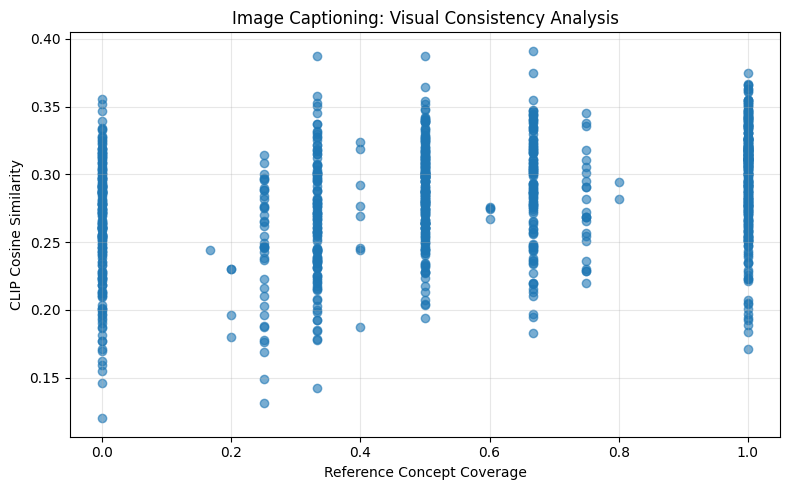

In [29]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    phase4_combined["reference_concept_coverage"],
    phase4_combined["clip_cosine_similarity"],
    alpha=0.6
)

plt.xlabel("Reference Concept Coverage")
plt.ylabel("CLIP Cosine Similarity")
plt.title("Image Captioning: Visual Consistency Analysis")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()